# Predicting Bank Account Ownership in East Africa
This notebook compares traditional ML and deep learning models for predicting
who owns a bank account in Kenya, Rwanda, Tanzania and Uganda,
using FinScope survey data (2016–2018).


In [ ]:
import os, random, glob, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

# Fix seeds so results are the same every run
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

# Change this if your folder name is different
BASE = "/content/drive/MyDrive/ML_Summative_Financial_Inclusion"
DATA_DIR = f"{BASE}/data"

# Find the zip and extract it
zip_path = glob.glob(f"{DATA_DIR}/*.zip")[0]
with zipfile.ZipFile(zip_path) as z:
    z.extractall("/content/raw")

df = pd.read_csv("/content/raw/Financial_inclusion_dataset.csv")
print("Raw shape:", df.shape)
df.head()

Mounted at /content/drive
Raw shape: (23524, 13)


,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


## 2. Exploratory Data Analysis
First we check data quality (types, missing values, duplicates),
then look at the class balance and how account ownership varies across groups.

In [ ]:
FIG_DIR = f"{BASE}/figures"
os.makedirs(FIG_DIR, exist_ok=True)

df.info()
print("\nMissing values per column:\n", df.isna().sum())

# Full-row duplicates (uniqueid makes every row look different, so ignore it)
dupes = df.drop(columns="uniqueid").duplicated().sum()
print("\nDuplicate rows (ignoring uniqueid):", dupes)

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   country                 23524 non-null  object
 1   year                    23524 non-null  int64 
 2   uniqueid                23524 non-null  object
 3   bank_account            23524 non-null  object
 4   location_type           23524 non-null  object
 5   cellphone_access        23524 non-null  object
 6   household_size          23524 non-null  int64 
 7   age_of_respondent       23524 non-null  int64 
 8   gender_of_respondent    23524 non-null  object
 9   relationship_with_head  23524 non-null  object
 10  marital_status          23524 non-null  object
 11  education_level         23524 non-null  object
 12  job_type                23524 non-null  object
dtypes: int64(3), object(10)
memory usage: 2.3+ MB

Missing values per column:
 country                   0
yea

,year,household_size,age_of_respondent
count,23524.000000,23524.000000,23524.000000
mean,2016.975939,3.797483,38.805220
std,0.847371,2.227613,16.520569
min,2016.000000,1.000000,16.000000
25%,2016.000000,2.000000,26.000000
50%,2017.000000,3.000000,35.000000
75%,2018.000000,5.000000,49.000000
max,2018.000000,21.000000,100.000000


bank_account
No     20212
Yes     3312
Name: count, dtype: int64

Share with an account: 14.08 %


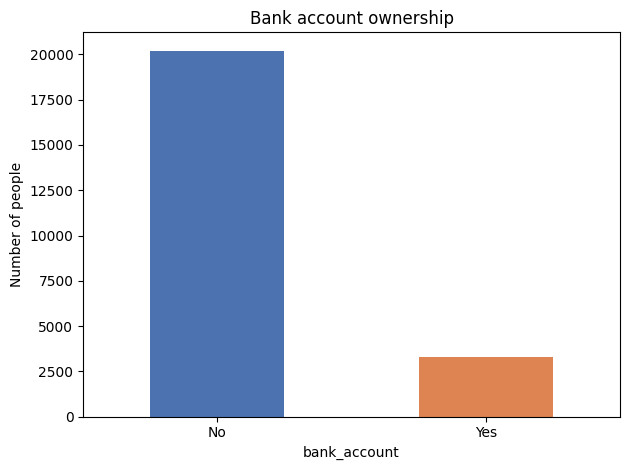

In [ ]:
counts = df["bank_account"].value_counts()
print(counts)
print("\nShare with an account:", round(counts["Yes"] / len(df) * 100, 2), "%")

ax = counts.plot(kind="bar", color=["#4C72B0", "#DD8452"])
ax.set_title("Bank account ownership")
ax.set_ylabel("Number of people")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/class_balance.png", dpi=150)
plt.show()

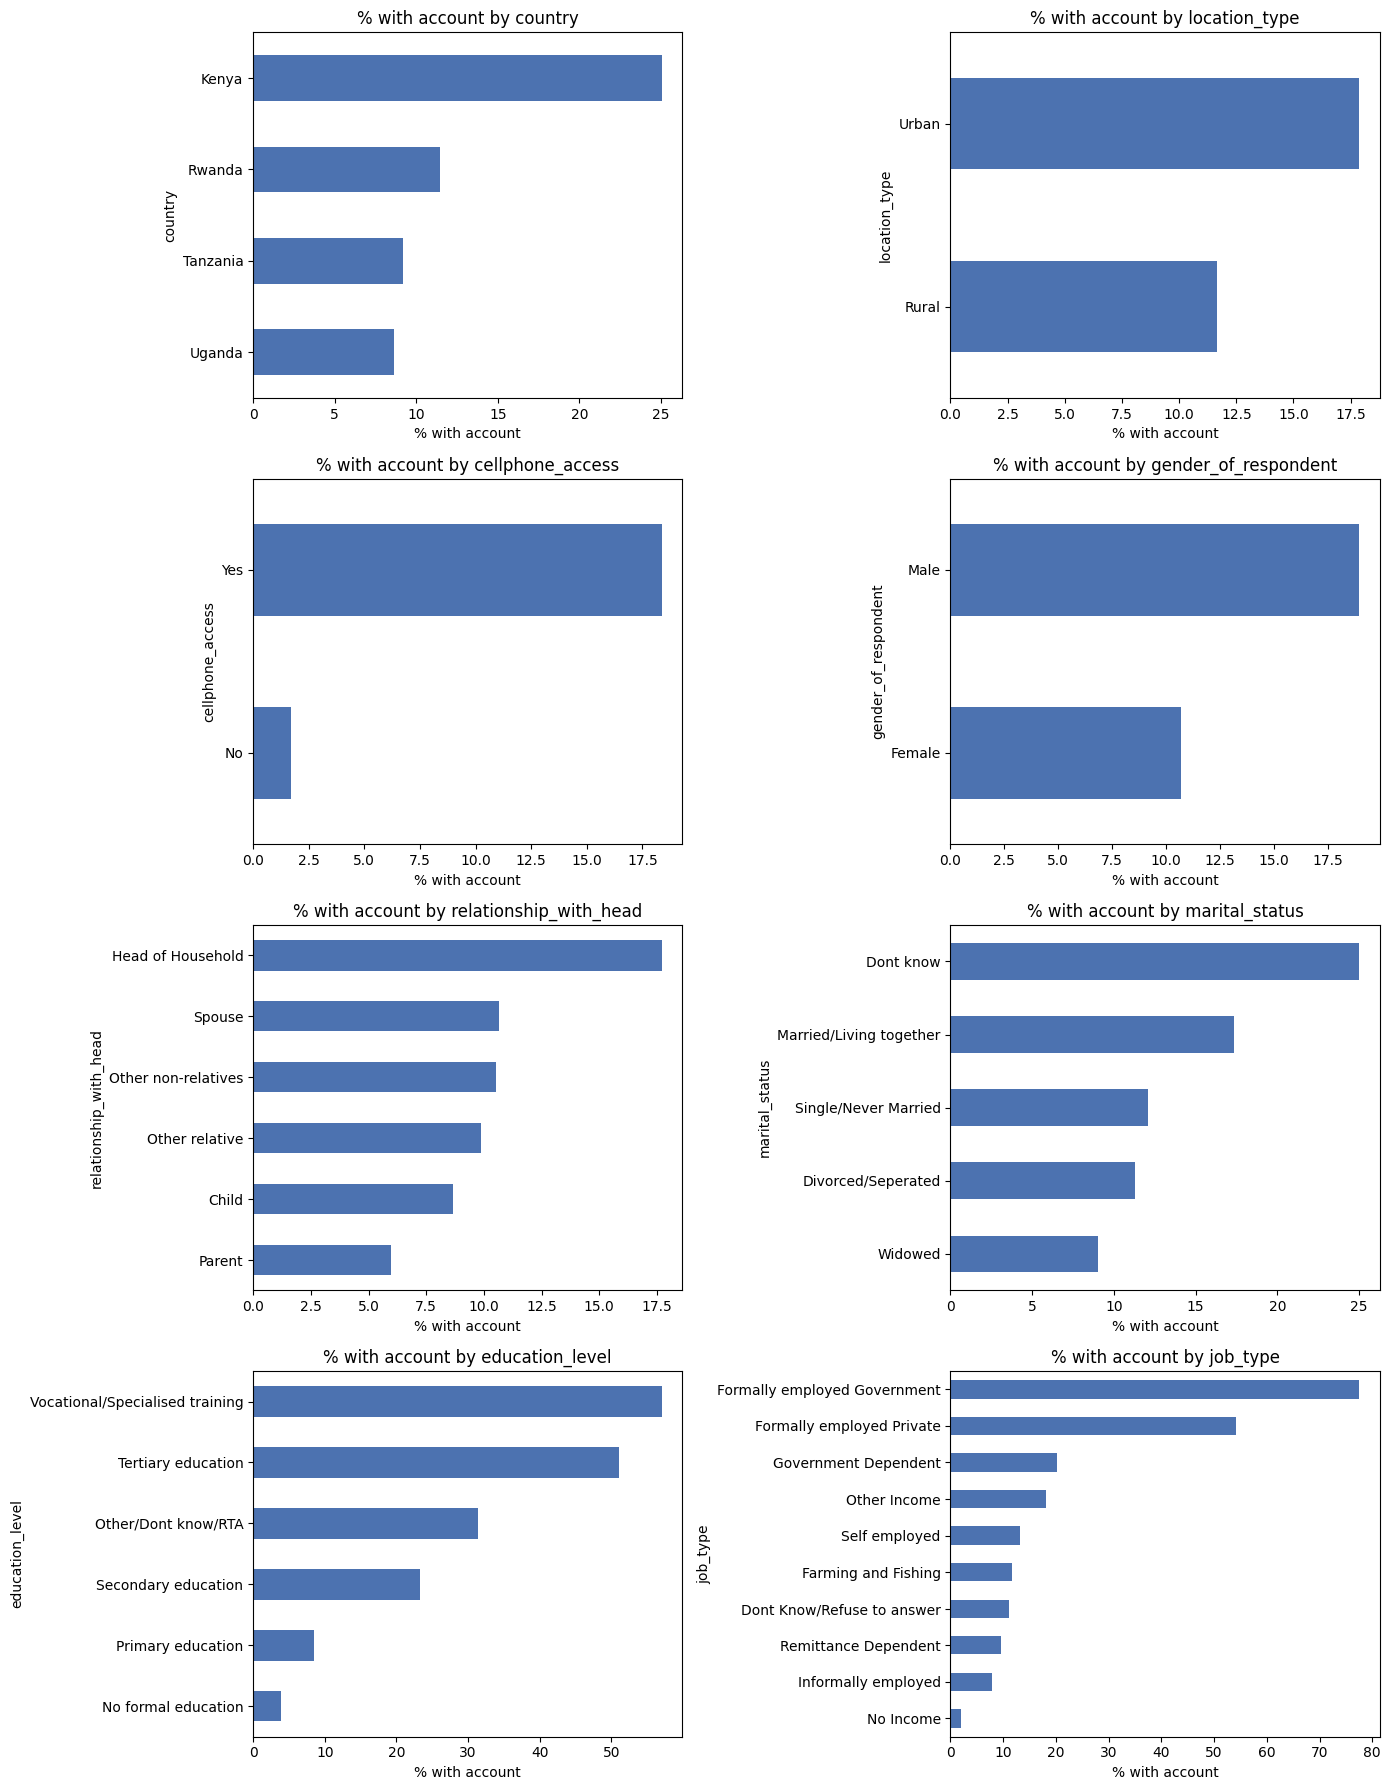

In [ ]:
df["has_account"] = (df["bank_account"] == "Yes").astype(int)

cat_cols = ["country", "location_type", "cellphone_access", "gender_of_respondent",
            "relationship_with_head", "marital_status", "education_level", "job_type"]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for ax, col in zip(axes.flat, cat_cols):
    rates = df.groupby(col)["has_account"].mean().sort_values() * 100
    rates.plot(kind="barh", ax=ax, color="#4C72B0")
    ax.set_title(f"% with account by {col}")
    ax.set_xlabel("% with account")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/account_rate_by_group.png", dpi=150)
plt.show()

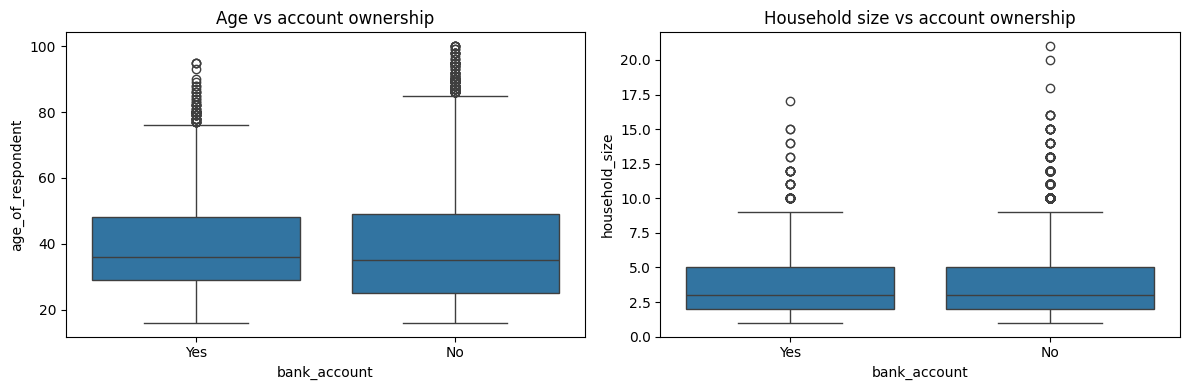

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="bank_account", y="age_of_respondent", ax=axes[0])
sns.boxplot(data=df, x="bank_account", y="household_size", ax=axes[1])
axes[0].set_title("Age vs account ownership")
axes[1].set_title("Household size vs account ownership")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/numeric_boxplots.png", dpi=150)
plt.show()

**What this shows:** Only 14.08% of respondents (3,312 out of 23,524) own a bank account,
so there are roughly 6 people without an account for every 1 with one.

This matters a lot for how we judge models. A model that predicts "No" for everyone
would already score about 86% accuracy while being completely useless. So accuracy
alone is misleading here. We will focus on precision, recall, F1, ROC-AUC and PR-AUC,
and test ways of handling the imbalance (class weights, SMOTE, threshold tuning).


**What this shows:** Account ownership is strongly tied to socioeconomic status.
Job type and education show the biggest gaps: formally employed government workers
are around 78% banked, while people with no formal education are around 4%.
Cellphone access also stands out, since people without a phone almost never have
an account. Kenya has a much higher rate (about 25%) than Rwanda, Tanzania and
Uganda (about 8–12%), which suggests country-level factors like banking
infrastructure play a role. Men, urban residents and household heads are also
more likely to be banked.

Some categories are very small (for example "Dont know" in marital status), so
their high or low rates may not be reliable. We will look at grouping rare
categories during preprocessing.

**What this shows:** Age and household size have very similar distributions for
both classes, so on their own they are weak predictors. Both have outliers
(ages up to 100, households of 20+). These look like real values rather than
errors, so instead of deleting them we will cap extreme values during
preprocessing. Age may still be useful when combined with other features,
so we will also try age bands in feature engineering.

In [ ]:
# Are the "duplicates" really different people?
real_dupes = df.duplicated(subset=["uniqueid", "country"]).sum()
print("Duplicates using uniqueid + country:", real_dupes)

# Do identical profiles ever have different answers?
feature_cols = [c for c in df.columns if c not in ["uniqueid", "bank_account", "has_account"]]
profile_labels = df.groupby(feature_cols)["bank_account"].nunique()
conflicts = (profile_labels > 1).sum()
print("Identical profiles with BOTH Yes and No:", conflicts)

Duplicates using uniqueid + country: 0
Identical profiles with BOTH Yes and No: 484


**Duplicates decision:** 4,429 rows (about 19%) are identical once `uniqueid` is removed.
However, checking `uniqueid` together with `country` shows zero true duplicates,
so every row is a different respondent. With only 11 mostly categorical features,
it is expected that many people share the same profile. Removing these rows would
throw away real survey responses, so we keep them.

We also found 484 identical profiles where some people have an account and others
do not. No model can separate these cases using the available features, so this
represents irreducible error (label noise) and puts an upper limit on achievable
performance.

## 3. Preprocessing
We drop the ID column, convert the target to 0/1, and split into train (70%),
validation (15%) and test (15%) sets, stratified so each set keeps the 14% positive rate.
Any step that learns from the data (outlier caps, rare category grouping, encoding,
scaling) is fitted on the training set only, to avoid data leakage.

In [ ]:
from sklearn.model_selection import train_test_split

data = df.drop(columns=["uniqueid", "has_account"]).copy()
y = (data.pop("bank_account") == "Yes").astype(int)
X = data

# 70% train, then split the rest 50/50 into validation and test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

for name, part in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"{name}: {len(part)} rows, {part.mean()*100:.2f}% with account")

Train: 16466 rows, 14.08% with account
Val: 3529 rows, 14.08% with account
Test: 3529 rows, 14.08% with account


In [ ]:
pd.crosstab(X_train["country"], X_train["year"])

year,2016,2017,2018
country,,,
Kenya,0,0,4244
Rwanda,6139,0,0
Tanzania,0,4653,0
Uganda,0,0,1430


**Year vs country:** Each country was surveyed in only one year (Rwanda 2016,
Tanzania 2017, Kenya and Uganda 2018), so `year` carries no information beyond
`country`. We keep it in the baseline feature set but drop it in the engineered set.
This also means country effects and time effects cannot be separated. For example,
Kenya's higher ownership rate could partly reflect its later survey date.

### Cleaning and feature engineering
- **Outliers:** age and household size are capped at the 1st and 99th percentiles
  of the training set. The extreme values look real, so we cap instead of deleting.
- **Rare categories:** categories with under 1% of training rows are grouped into "Other"
  so the models don't learn from tiny, unreliable groups.
- **Engineered features (based on EDA):** age bands, a household-head flag, a formal-job
  flag, a phone-and-urban interaction, and an ordered education rank.
- **Encoding:** numeric columns are standardized and categorical columns are one-hot encoded.

Everything is wrapped in one sklearn pipeline fitted on the training data only,
so the same steps apply to validation, test and any new data without leakage.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

def add_features(X):
    """New features based on what we saw in the EDA."""
    X = X.copy()
    X["age_band"] = pd.cut(X["age_of_respondent"], bins=[0, 24, 34, 49, 64, 200],
                           labels=["16-24", "25-34", "35-49", "50-64", "65+"]).astype(str)
    X["is_head"] = (X["relationship_with_head"] == "Head of Household").astype(int)
    X["formal_job"] = X["job_type"].isin(["Formally employed Government",
                                          "Formally employed Private"]).astype(int)
    X["phone_urban"] = ((X["cellphone_access"] == "Yes") &
                        (X["location_type"] == "Urban")).astype(int)
    edu_rank = {"No formal education": 0, "Primary education": 1,
                "Secondary education": 2, "Vocational/Specialised training": 3,
                "Tertiary education": 4}
    X["edu_unknown"] = (~X["education_level"].isin(edu_rank)).astype(int)
    X["education_rank"] = X["education_level"].map(edu_rank).fillna(1)  # unknown -> most common level
    return X.drop(columns=["year"])


class Cleaner(BaseEstimator, TransformerMixin):
    """Caps outliers, groups rare categories, and can add engineered features.
    Caps and rare categories are learned from the training data only."""
    def __init__(self, engineer=False, rare_min=0.01):
        self.engineer = engineer
        self.rare_min = rare_min

    def fit(self, X, y=None):
        # 1st and 99th percentile caps for the numeric columns
        self.caps_ = {c: X[c].quantile([0.01, 0.99]).values
                      for c in ["age_of_respondent", "household_size"]}
        # categories under 1% of rows get grouped as "Other"
        self.keep_ = {}
        for c in ["relationship_with_head", "marital_status", "job_type"]:
            share = X[c].value_counts(normalize=True)
            self.keep_[c] = share[share >= self.rare_min].index.tolist()
        return self

    def transform(self, X):
        X = X.copy()
        for c, (lo, hi) in self.caps_.items():
            X[c] = X[c].clip(lo, hi)
        for c, keep in self.keep_.items():
            X[c] = X[c].where(X[c].isin(keep), "Other")
        if self.engineer:
            X = add_features(X)
        return X

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

BASE_CATS = ["country", "location_type", "cellphone_access", "gender_of_respondent",
             "relationship_with_head", "marital_status", "education_level", "job_type"]

def make_preprocessor(engineer=False):
    if engineer:
        num = ["age_of_respondent", "household_size", "education_rank"]
        cats = BASE_CATS + ["age_band"]
        flags = ["is_head", "formal_job", "phone_urban", "edu_unknown"]
    else:
        num = ["age_of_respondent", "household_size", "year"]
        cats = BASE_CATS
        flags = []
    encode = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats),
        ("flag", "passthrough", flags),
    ])
    return Pipeline([("clean", Cleaner(engineer=engineer)), ("encode", encode)])

# Quick test: fit on train only, check the output size
for eng in [False, True]:
    prep = make_preprocessor(engineer=eng).fit(X_train)
    print(f"engineer={eng}: {prep.transform(X_train).shape[1]} features")

engineer=False: 40 features
engineer=True: 49 features


## 4. Experiment Tracking
Each experiment is evaluated on the validation set and logged in two places:
a results table (saved as CSV in Drive) and TensorBoard, so every number in the
report's experiment table can be traced back to a logged run. Because of the class
imbalance, we track precision, recall, F1, ROC-AUC and PR-AUC alongside accuracy.
The test set is only used once, at the end, for the final selected models.

In [ ]:
import json, time
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)

LOG_DIR = f"{BASE}/logs"
RESULTS_PATH = f"{BASE}/results.csv"
results = []

def log_experiment(exp_id, model_name, features, params, y_true, y_prob,
                   train_time, notes="", threshold=0.5):
    """Scores a run on the validation set, saves it to the table and TensorBoard."""
    y_pred = (y_prob >= threshold).astype(int)
    row = {
        "exp_id": exp_id, "model": model_name, "features": features,
        "params": json.dumps(params), "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "train_time_s": round(train_time, 2), "notes": notes,
    }
    # replace the row if this experiment was run before
    global results
    results = [r for r in results if r["exp_id"] != exp_id] + [row]
    pd.DataFrame(results).to_csv(RESULTS_PATH, index=False)

    writer = tf.summary.create_file_writer(f"{LOG_DIR}/{exp_id}")
    with writer.as_default():
        for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]:
            tf.summary.scalar(f"val/{k}", row[k], step=0)
        tf.summary.text("params", json.dumps(params), step=0)

    print({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})
    return row

## 5. Traditional Machine Learning
### E1: Logistic Regression baseline
A plain logistic regression on the baseline features with default settings.
This gives a reference point that every later experiment should beat.

In [ ]:
from sklearn.linear_model import LogisticRegression

e1 = Pipeline([("prep", make_preprocessor(engineer=False)),
               ("model", LogisticRegression(max_iter=1000, random_state=SEED))])

start = time.time()
e1.fit(X_train, y_train)
e1_time = time.time() - start

log_experiment("E1", "LogisticRegression", "baseline",
               {"C": 1.0, "class_weight": None},
               y_val, e1.predict_proba(X_val)[:, 1], e1_time,
               notes="Default baseline")

{'exp_id': 'E1', 'model': 'LogisticRegression', 'features': 'baseline', 'params': '{"C": 1.0, "class_weight": null}', 'threshold': 0.5, 'accuracy': 0.8855, 'precision': 0.6898, 'recall': 0.34, 'f1': 0.4555, 'roc_auc': np.float64(0.8641), 'pr_auc': np.float64(0.5772), 'train_time_s': 1.02, 'notes': 'Default baseline'}


{'exp_id': 'E1',
 'model': 'LogisticRegression',
 'features': 'baseline',
 'params': '{"C": 1.0, "class_weight": null}',
 'threshold': 0.5,
 'accuracy': 0.8855199773306885,
 'precision': 0.689795918367347,
 'recall': 0.34004024144869216,
 'f1': 0.4555256064690027,
 'roc_auc': np.float64(0.8640646650350652),
 'pr_auc': np.float64(0.5771555945131016),
 'train_time_s': 1.02,
 'notes': 'Default baseline'}

**E1 results:** Accuracy is 88.6%, but this is only 2.7 points above always
predicting "No" (85.9%). Recall is just 34%, so the model misses about two thirds
of people who own an account. Precision (69%) is much higher than recall, which
means the model is too conservative: the default 0.5 threshold is poorly suited to
a 14% minority class. The ROC-AUC of 0.864 shows the model ranks people reasonably
well, so the next step is to address the imbalance and test our engineered features.

### E2: Logistic Regression with class weights, engineered features and tuned C
We run a grid search with 5-fold stratified cross-validation on the training set,
testing both feature sets, with and without balanced class weights, across
four regularization strengths. This shows the effect of each change separately.
F1 is used as the selection metric because it balances precision and recall.

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

lr_pipe = Pipeline([("prep", make_preprocessor(engineer=False)),
                    ("model", LogisticRegression(max_iter=2000, random_state=SEED))])

lr_grid = {
    "prep": [make_preprocessor(engineer=False), make_preprocessor(engineer=True)],
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"],
}

start = time.time()
e2_search = GridSearchCV(lr_pipe, lr_grid, scoring="f1", cv=cv, n_jobs=-1)
e2_search.fit(X_train, y_train)
e2_time = time.time() - start

# Readable summary of every combination (useful for the report)
cvres = pd.DataFrame(e2_search.cv_results_)
cvres["features"] = cvres["param_prep"].apply(lambda p: "engineered" if p.steps[0][1].engineer else "baseline")
print(cvres[["features", "param_model__C", "param_model__class_weight", "mean_test_score"]]
      .sort_values("mean_test_score", ascending=False).round(4).to_string(index=False))

best = e2_search.best_params_
e2 = e2_search.best_estimator_
log_experiment("E2", "LogisticRegression",
               "engineered" if best["prep"].steps[0][1].engineer else "baseline",
               {"C": best["model__C"], "class_weight": best["model__class_weight"]},
               y_val, e2.predict_proba(X_val)[:, 1], e2_time,
               notes=f"GridSearch 5-fold, best CV F1={e2_search.best_score_:.4f}")

  features  param_model__C param_model__class_weight  mean_test_score
engineered           10.00                  balanced           0.4983
engineered            1.00                  balanced           0.4976
engineered            0.10                  balanced           0.4972
engineered            0.01                  balanced           0.4958
  baseline            1.00                  balanced           0.4929
  baseline           10.00                  balanced           0.4923
  baseline            0.10                  balanced           0.4913
  baseline            0.01                  balanced           0.4820
engineered           10.00                      None           0.4602
engineered            1.00                      None           0.4590
engineered            0.10                      None           0.4520
  baseline           10.00                      None           0.4494
  baseline            1.00                      None           0.4484
  baseline          

{'exp_id': 'E2',
 'model': 'LogisticRegression',
 'features': 'engineered',
 'params': '{"C": 10, "class_weight": "balanced"}',
 'threshold': 0.5,
 'accuracy': 0.7959761972230094,
 'precision': 0.3874873864783047,
 'recall': 0.772635814889336,
 'f1': 0.5161290322580645,
 'roc_auc': np.float64(0.8635278027001057),
 'pr_auc': np.float64(0.5753500910806155),
 'train_time_s': 28.16,
 'notes': 'GridSearch 5-fold, best CV F1=0.4983'}

**E2 results:** Balanced class weights had the largest effect. Every weighted
configuration outperformed every unweighted one in cross-validation. Engineered
features gave a small but consistent gain (about 0.5 F1 points) at every value of C,
while C itself mattered little except at strong regularization without weights.

On the validation set, recall rose from 34% to 77% and F1 from 0.456 to 0.516,
but precision fell from 69% to 39%. This is the expected precision-recall trade-off:
weighting pushes the model to flag more people as banked.

Importantly, ROC-AUC stayed almost the same (0.864). Class weights change where the
decision boundary sits, but not how well the model ranks people. To improve ranking,
we need models that can capture non-linear interactions between features, such as
tree-based ensembles.

### E3: Random Forest
Random Forests can learn interactions between features without us defining them.
We tune the number of trees, maximum depth and minimum samples per leaf, using
balanced class weights and engineered features (the best settings from E2).

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([("prep", make_preprocessor(engineer=True)),
                    ("model", RandomForestClassifier(class_weight="balanced",
                                                     random_state=SEED, n_jobs=-1))])

rf_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [1, 5, 10],
}

start = time.time()
e3_search = GridSearchCV(rf_pipe, rf_grid, scoring="f1", cv=cv, n_jobs=-1)
e3_search.fit(X_train, y_train)
e3_time = time.time() - start

cvres3 = pd.DataFrame(e3_search.cv_results_)
print(cvres3[["param_model__n_estimators", "param_model__max_depth",
              "param_model__min_samples_leaf", "mean_test_score", "mean_train_score"
              if "mean_train_score" in cvres3 else "std_test_score"]]
      .sort_values("mean_test_score", ascending=False).round(4).to_string(index=False))

best3 = {k.replace("model__", ""): v for k, v in e3_search.best_params_.items()}
e3 = e3_search.best_estimator_
log_experiment("E3", "RandomForest", "engineered",
               {**best3, "class_weight": "balanced"},
               y_val, e3.predict_proba(X_val)[:, 1], e3_time,
               notes=f"GridSearch 5-fold, best CV F1={e3_search.best_score_:.4f}")

 param_model__n_estimators param_model__max_depth  param_model__min_samples_leaf  mean_test_score  std_test_score
                       400                   None                              5           0.5240          0.0210
                       400                     20                              5           0.5235          0.0200
                       200                     20                              5           0.5218          0.0210
                       200                   None                              5           0.5214          0.0193
                       200                     10                              1           0.5163          0.0162
                       400                     10                              1           0.5154          0.0173
                       400                     10                              5           0.5142          0.0158
                       200                     10                              5        

{'exp_id': 'E3',
 'model': 'RandomForest',
 'features': 'engineered',
 'params': '{"max_depth": null, "min_samples_leaf": 5, "n_estimators": 400, "class_weight": "balanced"}',
 'threshold': 0.5,
 'accuracy': 0.8237461037120998,
 'precision': 0.42568370986920334,
 'recall': 0.7203219315895373,
 'f1': 0.5351270553064275,
 'roc_auc': np.float64(0.870966564558857),
 'pr_auc': np.float64(0.5889970383325456),
 'train_time_s': 378.96,
 'notes': 'GridSearch 5-fold, best CV F1=0.5240'}

**E3 results:** Minimum samples per leaf was the most important setting. Fully grown
trees with a leaf size of 1 overfit badly (CV F1 around 0.43), because each tree
memorizes individual respondents. A leaf size of 5 gave the best results. Limiting
depth to 10 also reduced overfitting, showing two different ways of controlling
model variance. The number of trees had almost no effect.

The best Random Forest outperformed logistic regression on every ranking metric
(F1 0.535 vs 0.516, ROC-AUC 0.871 vs 0.864, PR-AUC 0.589 vs 0.575), confirming that
non-linear interactions add some signal. However, the gain is modest and training
took over 13 times longer. This suggests the main limit is the information in the
features rather than model complexity, consistent with the label noise found earlier.

### E4: Gradient Boosting (XGBoost)
Gradient boosting builds trees one after another, each correcting the errors of the
previous ones, and often beats Random Forests on tabular data. We use a randomized
search (25 combinations) because the search space is larger. The class imbalance is
handled with `scale_pos_weight`, set to the ratio of negatives to positives.

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(pos_weight, 2))

xgb_pipe = Pipeline([("prep", make_preprocessor(engineer=True)),
                     ("model", XGBClassifier(tree_method="hist", eval_metric="logloss",
                                             scale_pos_weight=pos_weight,
                                             random_state=SEED, n_jobs=-1))])

xgb_space = {
    "model__n_estimators": [200, 400],            # removed 800
    "model__learning_rate": [0.05, 0.1, 0.2],     # removed 0.01
    "model__max_depth": [3, 4, 6],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 1.0],
    "model__min_child_weight": [1, 5],
}

start = time.time()
e4_search = RandomizedSearchCV(xgb_pipe, xgb_space, n_iter=15, scoring="f1",   # 15 instead of 25
                               cv=cv, random_state=SEED, n_jobs=1)
e4_search.fit(X_train, y_train)
e4_time = time.time() - start

cvres4 = pd.DataFrame(e4_search.cv_results_)
cols = [c for c in cvres4.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
print(cvres4[cols].sort_values("mean_test_score", ascending=False)
      .head(10).round(4).to_string(index=False))

best4 = {k.replace("model__", ""): v for k, v in e4_search.best_params_.items()}
e4 = e4_search.best_estimator_
log_experiment("E4", "XGBoost", "engineered",
               {**best4, "scale_pos_weight": round(pos_weight, 2)},
               y_val, e4.predict_proba(X_val)[:, 1], e4_time,
               notes=f"RandomizedSearch 15 iters 5-fold, best CV F1={e4_search.best_score_:.4f}")

scale_pos_weight: 6.1
 param_model__subsample  param_model__n_estimators  param_model__min_child_weight  param_model__max_depth  param_model__learning_rate  param_model__colsample_bytree  mean_test_score  std_test_score
                   0.70                        200                              5                       6                        0.05                            0.7           0.5119          0.0153
                   0.85                        200                              5                       6                        0.05                            1.0           0.5085          0.0193
                   0.70                        400                              1                       4                        0.05                            0.7           0.5075          0.0144
                   0.85                        200                              5                       6                        0.10                            0.7           0.5068     

{'exp_id': 'E4',
 'model': 'XGBoost',
 'features': 'engineered',
 'params': '{"subsample": 0.7, "n_estimators": 200, "min_child_weight": 5, "max_depth": 6, "learning_rate": 0.05, "colsample_bytree": 0.7, "scale_pos_weight": 6.1}',
 'threshold': 0.5,
 'accuracy': 0.8022102578634174,
 'precision': 0.3981762917933131,
 'recall': 0.7907444668008048,
 'f1': 0.5296495956873315,
 'roc_auc': np.float64(0.8745527253229136),
 'pr_auc': np.float64(0.5961782970502558),
 'train_time_s': 87.17,
 'notes': 'RandomizedSearch 15 iters 5-fold, best CV F1=0.5119'}

**E4 results:** XGBoost achieved the best ranking performance so far
(ROC-AUC 0.875, PR-AUC 0.596), but a slightly lower F1 than the Random Forest
(0.530 vs 0.535). The high `scale_pos_weight` pushes the model toward predicting
"Yes", giving high recall (79%) but low precision (40%) at the default 0.5 threshold.
This shows that F1 at a fixed threshold can hide differences in ranking quality,
which we address with threshold tuning in E6.

The best configurations used a lower learning rate (0.05) with row and column
subsampling (0.7), while a learning rate of 0.2 performed worse. Smaller update
steps combined with subsampling act as regularization and reduce overfitting.

### E5: Support Vector Machine (RBF kernel)
SVM training time grows roughly with the square of the number of samples, so a full
grid search on 16,466 rows would be very slow. We therefore tune C and gamma on a
stratified sample of 6,000 training rows with 3-fold CV, then retrain the best setting
on the full training set. SVMs output decision scores rather than probabilities,
so we use the scores for ROC-AUC and PR-AUC and a threshold of 0 for class predictions.

In [ ]:
from sklearn.svm import SVC

# Stratified sample for tuning
X_small, _, y_small, _ = train_test_split(X_train, y_train, train_size=6000,
                                          stratify=y_train, random_state=SEED)

svm_pipe = Pipeline([("prep", make_preprocessor(engineer=True)),
                     ("model", SVC(kernel="rbf", class_weight="balanced", random_state=SEED))])

svm_grid = {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01]}
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

start = time.time()
e5_search = GridSearchCV(svm_pipe, svm_grid, scoring="f1", cv=cv3, n_jobs=-1)
e5_search.fit(X_small, y_small)

cvres5 = pd.DataFrame(e5_search.cv_results_)
print(cvres5[["param_model__C", "param_model__gamma", "mean_test_score", "std_test_score"]]
      .sort_values("mean_test_score", ascending=False).round(4).to_string(index=False))

# Retrain the best setting on the full training set
e5 = e5_search.best_estimator_.fit(X_train, y_train)
e5_time = time.time() - start

best5 = {k.replace("model__", ""): v for k, v in e5_search.best_params_.items()}
log_experiment("E5", "SVM (RBF)", "engineered",
               {**best5, "class_weight": "balanced"},
               y_val, e5.decision_function(X_val), e5_time, threshold=0.0,
               notes=f"Tuned on 6k sample 3-fold (CV F1={e5_search.best_score_:.4f}), refit on full train")


 param_model__C param_model__gamma  mean_test_score  std_test_score
            0.1              scale           0.4971          0.0141
            1.0               0.01           0.4943          0.0105
           10.0               0.01           0.4918          0.0050
            1.0              scale           0.4898          0.0083
            0.1               0.01           0.4825          0.0203
           10.0              scale           0.4492          0.0084
{'exp_id': 'E5', 'model': 'SVM (RBF)', 'features': 'engineered', 'params': '{"C": 0.1, "gamma": "scale", "class_weight": "balanced"}', 'threshold': 0.0, 'accuracy': 0.7875, 'precision': 0.3763, 'recall': 0.7746, 'f1': 0.5066, 'roc_auc': np.float64(0.8669), 'pr_auc': np.float64(0.5206), 'train_time_s': 48.25, 'notes': 'Tuned on 6k sample 3-fold (CV F1=0.4971), refit on full train'}


{'exp_id': 'E5',
 'model': 'SVM (RBF)',
 'features': 'engineered',
 'params': '{"C": 0.1, "gamma": "scale", "class_weight": "balanced"}',
 'threshold': 0.0,
 'accuracy': 0.7874752054406348,
 'precision': 0.3763440860215054,
 'recall': 0.7746478873239436,
 'f1': 0.506578947368421,
 'roc_auc': np.float64(0.8669434151080626),
 'pr_auc': np.float64(0.5206052334411062),
 'train_time_s': 48.25,
 'notes': 'Tuned on 6k sample 3-fold (CV F1=0.4971), refit on full train'}

**E5 results:** The SVM was the weakest model, with an F1 of 0.507 and the lowest
PR-AUC of all experiments (0.521). Its ROC-AUC (0.867) was comparable to logistic
regression, but PR-AUC focuses on the highest-ranked predictions, where the minority
class matters most, and the SVM's decision scores were less reliable there. The
smallest C (0.1) performed best, while C=10 with the default gamma overfit noticeably,
showing again that strong regularization suits this noisy dataset. Because tuning was
done on a 6,000-row sample for computational reasons, the chosen settings may not be
optimal for the full training set. Given its higher cost, lack of native probabilities
and weaker results, the SVM is not a strong candidate for this problem.

### E6: Imbalance strategies and threshold tuning
Using the best XGBoost and Random Forest settings, we compare:
- **E6a:** SMOTE oversampling with no class weights (default 0.5 threshold)
- **E6b:** XGBoost with no weighting, plus a tuned threshold
- **E6c:** XGBoost with class weights, plus a tuned threshold
- **E6d:** Random Forest with class weights, plus a tuned threshold

The threshold is chosen to maximize F1 on out-of-fold predictions from 5-fold CV
on the training set, then applied unchanged to the validation set. This avoids
tuning and evaluating on the same data. One known weakness of SMOTE here is that it
creates in-between values for one-hot encoded columns, which do not correspond to
real categories.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

xgb_params = {k.replace("model__", ""): v for k, v in e4_search.best_params_.items()}

def make_xgb(weight):
    return XGBClassifier(tree_method="hist", eval_metric="logloss", scale_pos_weight=weight,
                         random_state=SEED, n_jobs=-1, **xgb_params)

def best_threshold(y_true, y_prob):
    """Threshold that gives the highest F1."""
    p, r, t = precision_recall_curve(y_true, y_prob)
    f1 = 2 * p * r / (p + r + 1e-9)
    return float(t[np.argmax(f1[:-1])])

def run_with_threshold(exp_id, name, pipe, params, notes):
    start = time.time()
    oof = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    t = best_threshold(y_train, oof)
    pipe.fit(X_train, y_train)
    log_experiment(exp_id, name, "engineered", params, y_val,
                   pipe.predict_proba(X_val)[:, 1], time.time() - start,
                   threshold=round(t, 3), notes=notes)
    return pipe, t

# E6a: SMOTE, no weights, default threshold
start = time.time()
prep_steps = make_preprocessor(engineer=True).steps   # [("clean", ...), ("encode", ...)]
e6a = ImbPipeline(prep_steps + [("smote", SMOTE(random_state=SEED)),
                                ("model", make_xgb(1))]).fit(X_train, y_train)
log_experiment("E6a", "XGBoost + SMOTE", "engineered", {**xgb_params, "scale_pos_weight": 1},
               y_val, e6a.predict_proba(X_val)[:, 1], time.time() - start,
               notes="SMOTE oversampling, threshold 0.5")

# E6b: no weights, tuned threshold
e6b, t6b = run_with_threshold("E6b", "XGBoost",
                              Pipeline([("prep", make_preprocessor(engineer=True)),
                                        ("model", make_xgb(1))]),
                              {**xgb_params, "scale_pos_weight": 1},
                              "No weighting, tuned threshold")

# E6c: class weights, tuned threshold
e6c, t6c = run_with_threshold("E6c", "XGBoost", clone(e4),
                              {**xgb_params, "scale_pos_weight": round(pos_weight, 2)},
                              "Weighted, tuned threshold")

# E6d: Random Forest, class weights, tuned threshold
e6d, t6d = run_with_threshold("E6d", "RandomForest", clone(e3),
                              {**best3, "class_weight": "balanced"},
                              "Weighted, tuned threshold")

{'exp_id': 'E6a', 'model': 'XGBoost + SMOTE', 'features': 'engineered', 'params': '{"subsample": 0.7, "n_estimators": 200, "min_child_weight": 5, "max_depth": 6, "learning_rate": 0.05, "colsample_bytree": 0.7, "scale_pos_weight": 1}', 'threshold': 0.5, 'accuracy': 0.8782, 'precision': 0.5696, 'recall': 0.5513, 'f1': 0.5603, 'roc_auc': np.float64(0.8652), 'pr_auc': np.float64(0.5772), 'train_time_s': 10.17, 'notes': 'SMOTE oversampling, threshold 0.5'}
{'exp_id': 'E6b', 'model': 'XGBoost', 'features': 'engineered', 'params': '{"subsample": 0.7, "n_estimators": 200, "min_child_weight": 5, "max_depth": 6, "learning_rate": 0.05, "colsample_bytree": 0.7, "scale_pos_weight": 1}', 'threshold': 0.251, 'accuracy': 0.86, 'precision': 0.5024, 'recall': 0.6298, 'f1': 0.5589, 'roc_auc': np.float64(0.8773), 'pr_auc': np.float64(0.6018), 'train_time_s': 6.36, 'notes': 'No weighting, tuned threshold'}
{'exp_id': 'E6c', 'model': 'XGBoost', 'features': 'engineered', 'params': '{"subsample": 0.7, "n_esti

**E6 results:** Threshold tuning gave a larger improvement than any hyperparameter
search. All four strategies reached an F1 of 0.554 to 0.560, compared with 0.530 to
0.535 at the default threshold.

The comparison between E6b and E6c is especially revealing. The unweighted model chose
a threshold of 0.25, while the weighted model chose 0.64, yet both reached almost the
same precision, recall and F1. Class weights inflate the predicted probabilities for the
minority class, and the tuned threshold simply moves to compensate. In other words,
weighting and threshold tuning are two routes to the same decision boundary.

SMOTE achieved the highest F1 (0.560), but by only 0.001, and it reduced ranking quality
(PR-AUC 0.577 vs 0.602), likely because synthetic samples contain unrealistic in-between
values for one-hot encoded categories. Since the F1 differences between these strategies
are smaller than the cross-validation standard deviation (about 0.015 to 0.02), we treat
them as equivalent on F1 and select **E6b** as the best traditional model. It has the
best ROC-AUC (0.877) and PR-AUC (0.602) of all experiments, avoids synthetic data,
and trains in about 6 seconds.

## 6. Deep Learning (TensorFlow / Keras)
We reuse the same engineered preprocessing pipeline, fitted on the training set,
and feed the data through `tf.data` pipelines (shuffling, batching and prefetching).
Every run is logged with the TensorBoard callback and added to the same results table.
We track loss, ROC-AUC and PR-AUC on training and validation data to diagnose
underfitting and overfitting from the learning curves.

In [ ]:
from tensorflow.keras import layers

# Same preprocessing as the ML models, fitted on train only
prep_dl = make_preprocessor(engineer=True).fit(X_train)
Xtr = prep_dl.transform(X_train).astype("float32")
Xva = prep_dl.transform(X_val).astype("float32")
Xte = prep_dl.transform(X_test).astype("float32")
ytr = y_train.values.astype("float32")
yva = y_val.values.astype("float32")
yte = y_test.values.astype("float32")
N_FEATURES = Xtr.shape[1]

def make_ds(X, y, batch, shuffle=False):
    """tf.data pipeline: shuffle (train only), batch, prefetch."""
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

def build_mlp(units=(128, 64), dropout=0.0, l2=0.0, lr=1e-3):
    """Sequential MLP with optional dropout and L2."""
    tf.keras.utils.set_random_seed(SEED)
    reg = tf.keras.regularizers.l2(l2) if l2 else None
    model = tf.keras.Sequential([tf.keras.Input(shape=(N_FEATURES,))])
    for u in units:
        model.add(layers.Dense(u, activation="relu", kernel_regularizer=reg))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[tf.keras.metrics.AUC(name="auc"),
                           tf.keras.metrics.AUC(curve="PR", name="pr_auc")])
    return model

def plot_curves(hist, exp_id):
    """Training vs validation loss and PR-AUC."""
    h = hist.history
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="val")
    axes[0].set_title(f"{exp_id} loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(h["pr_auc"], label="train"); axes[1].plot(h["val_pr_auc"], label="val")
    axes[1].set_title(f"{exp_id} PR-AUC"); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/learning_curve_{exp_id}.png", dpi=150)
    plt.show()

def train_dl(exp_id, model, params, epochs=50, batch=256, early_stop=False,
             class_weight=None, threshold=0.5, notes=""):
    train_ds = make_ds(Xtr, ytr, batch, shuffle=True)
    val_ds = make_ds(Xva, yva, batch)
    callbacks = [tf.keras.callbacks.TensorBoard(log_dir=f"{LOG_DIR}/{exp_id}")]
    if early_stop:
        callbacks.append(tf.keras.callbacks.EarlyStopping(
            monitor="val_pr_auc", mode="max", patience=8, restore_best_weights=True))
    start = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     callbacks=callbacks, class_weight=class_weight, verbose=0)
    train_time = time.time() - start
    y_prob = model.predict(val_ds, verbose=0).ravel()
    params = {**params, "epochs_run": len(hist.history["loss"]), "batch": batch}
    log_experiment(exp_id, "MLP (Keras)", "engineered", params, y_val, y_prob,
                   train_time, threshold=threshold, notes=notes)
    plot_curves(hist, exp_id)
    return model, hist

print("Input features:", N_FEATURES)

Input features: 49


### E7: Baseline MLP (no regularization)
A simple two-layer network (128 and 64 units, ReLU) trained for 50 epochs with
no dropout, no L2 and no early stopping. This is deliberately unregularized so we
can see how quickly it overfits on the learning curves.

{'exp_id': 'E7', 'model': 'MLP (Keras)', 'features': 'engineered', 'params': '{"units": [128, 64], "dropout": 0, "l2": 0, "lr": 0.001, "epochs_run": 50, "batch": 256}', 'threshold': 0.5, 'accuracy': 0.8779, 'precision': 0.5859, 'recall': 0.4527, 'f1': 0.5108, 'roc_auc': np.float64(0.8472), 'pr_auc': np.float64(0.5386), 'train_time_s': 38.38, 'notes': 'Unregularized baseline, no early stopping'}


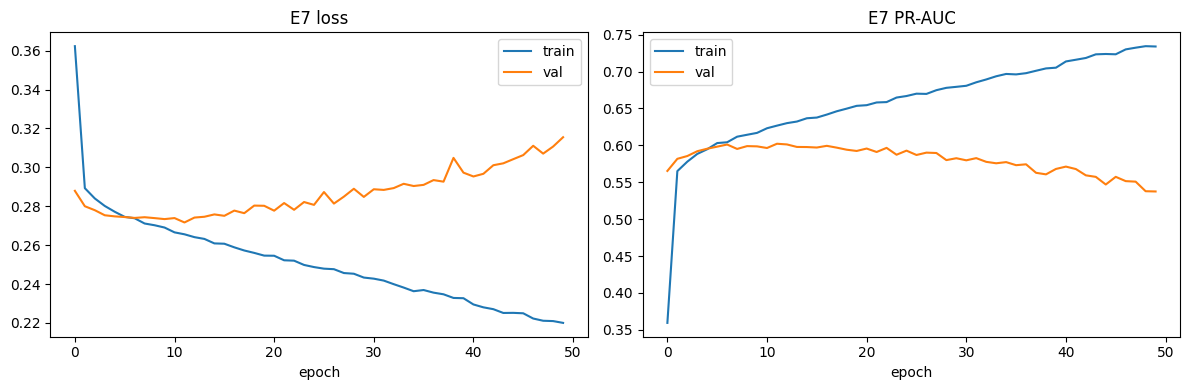

In [ ]:
e7_model, e7_hist = train_dl("E7", build_mlp(units=(128, 64)),
                             {"units": [128, 64], "dropout": 0, "l2": 0, "lr": 1e-3},
                             epochs=50, notes="Unregularized baseline, no early stopping")

**E7 results:** The learning curves show clear overfitting. Training and validation
loss fall together for the first 8 to 10 epochs, after which training loss keeps
dropping (to about 0.22) while validation loss rises from about 0.27 to 0.31.
Validation PR-AUC peaks at around 0.60 between epochs 5 and 12 and then declines to
about 0.54, while training PR-AUC climbs to 0.73. The growing gap between the curves
is a sign of high variance: the network starts memorizing training respondents instead
of learning general patterns. Notably, it briefly matched the best tree models before
overfitting, which suggests that regularization and early stopping should recover that
performance.

### E8: Adding dropout, L2 regularization and early stopping
Same architecture as E7, with dropout (0.3) after each hidden layer, L2 weight
penalty (1e-4), and early stopping on validation PR-AUC (patience 8), restoring the
best weights. The epoch limit is raised to 100 since early stopping decides when to stop.

{'exp_id': 'E8', 'model': 'MLP (Keras)', 'features': 'engineered', 'params': '{"units": [128, 64], "dropout": 0.3, "l2": 0.0001, "lr": 0.001, "epochs_run": 20, "batch": 256}', 'threshold': 0.5, 'accuracy': 0.8881, 'precision': 0.6809, 'recall': 0.3863, 'f1': 0.4929, 'roc_auc': np.float64(0.875), 'pr_auc': np.float64(0.5988), 'train_time_s': 19.15, 'notes': 'Dropout + L2 + early stopping (patience 8)'}


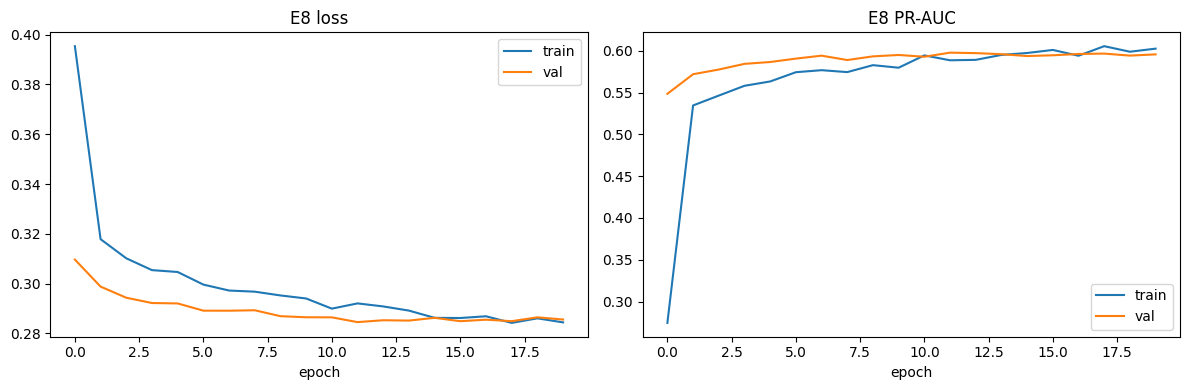

In [ ]:
e8_model, e8_hist = train_dl("E8", build_mlp(units=(128, 64), dropout=0.3, l2=1e-4),
                             {"units": [128, 64], "dropout": 0.3, "l2": 1e-4, "lr": 1e-3},
                             epochs=100, early_stop=True,
                             notes="Dropout + L2 + early stopping (patience 8)")

In [ ]:
show = ["exp_id", "model", "threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "train_time_s"]
pd.DataFrame(results)[show].round(4)

,exp_id,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_s
0,E1,LogisticRegression,0.500,0.8855,0.6898,0.3400,0.4555,0.8641,0.5772,1.02
1,E2,LogisticRegression,0.500,0.7960,0.3875,0.7726,0.5161,0.8635,0.5754,28.16
2,E3,RandomForest,0.500,0.8237,0.4257,0.7203,0.5351,0.8710,0.5890,378.96
3,E4,XGBoost,0.500,0.8022,0.3982,0.7907,0.5296,0.8746,0.5962,87.17
4,E5,SVM (RBF),0.000,0.7875,0.3763,0.7746,0.5066,0.8669,0.5206,48.25
5,E6a,XGBoost + SMOTE,0.500,0.8782,0.5696,0.5513,0.5603,0.8652,0.5772,10.17
6,E6b,XGBoost,0.251,0.8600,0.5024,0.6298,0.5589,0.8773,0.6018,6.36
7,E6c,XGBoost,0.640,0.8555,0.4900,0.6378,0.5542,0.8746,0.5962,8.25
8,E6d,RandomForest,0.595,0.8592,0.5000,0.6278,0.5566,0.8710,0.5890,37.09
9,E7,MLP (Keras),0.500,0.8779,0.5859,0.4527,0.5108,0.8472,0.5386,38.38


**E8 results:** Regularization removed the overfitting seen in E7. Training and
validation curves now track each other closely (loss around 0.285, PR-AUC around 0.60),
so the gap that signalled high variance is gone. Validation loss is slightly below
training loss in early epochs because dropout is only active during training.
Early stopping halted training after about 20 epochs and restored the best weights,
avoiding the decline seen in E7. Validation PR-AUC now stays stable at about 0.60,
close to the best XGBoost model.

In numbers, regularization raised validation ROC-AUC from 0.847 to 0.875 and PR-AUC
from 0.539 to 0.599, matching the tuned XGBoost (E4) in ranking quality. However, F1
at the default 0.5 threshold fell to 0.493 (precision 68%, recall 39%), the same
conservative pattern seen in the unweighted logistic regression (E1). This is a
threshold issue rather than a weaker model, and is addressed in E11.

### E9: Functional API with categorical embeddings
Instead of one-hot encoding, each categorical feature is passed through a
`StringLookup` layer and its own `Embedding` layer, letting the network learn a dense
representation of each category. Numeric and flag features are standardized and fed
through a separate input. This requires the Functional API, since the model has
multiple inputs. Regularization and early stopping follow E8.

{'exp_id': 'E9', 'model': 'Embedding MLP (Functional)', 'features': 'engineered + embeddings', 'params': '{"units": [128, 64], "dropout": 0.3, "l2": 0.0001, "lr": 0.001, "emb_dim": "min(8,(n+1)//2)", "epochs_run": 50, "batch": 256}', 'threshold': 0.5, 'accuracy': 0.8889, 'precision': 0.6733, 'recall': 0.4105, 'f1': 0.51, 'roc_auc': np.float64(0.8741), 'pr_auc': np.float64(0.602), 'train_time_s': 66.13, 'notes': 'Functional API, StringLookup + Embedding per categorical'}


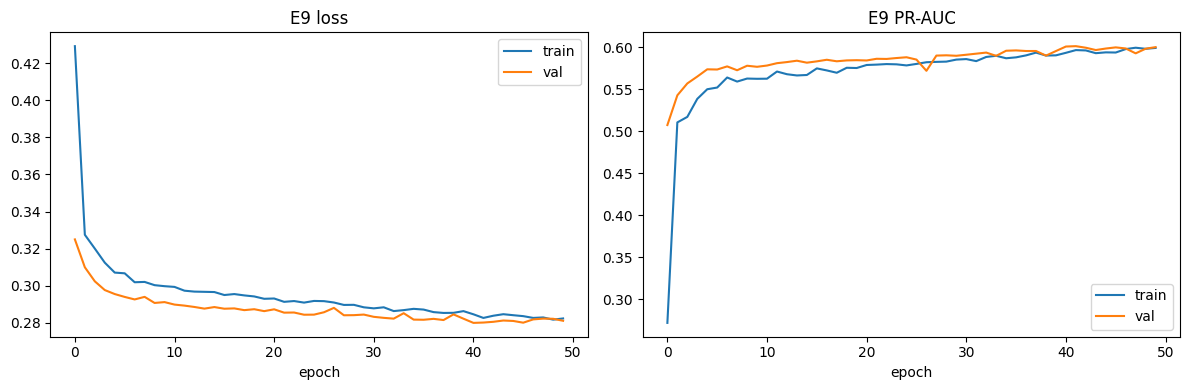

In [ ]:
# Clean and engineer features (fitted on train), but keep categories as strings
clean = Cleaner(engineer=True).fit(X_train)
Ctr, Cva, Cte = clean.transform(X_train), clean.transform(X_val), clean.transform(X_test)

EMB_CATS = BASE_CATS + ["age_band"]
EMB_NUMS = ["age_of_respondent", "household_size", "education_rank",
            "is_head", "formal_job", "phone_urban", "edu_unknown"]

num_scaler = StandardScaler().fit(Ctr[EMB_NUMS])

def to_inputs(C):
    d = {c: C[c].astype(str).values for c in EMB_CATS}
    d["num"] = num_scaler.transform(C[EMB_NUMS]).astype("float32")
    return d

def make_emb_ds(C, y, batch=256, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((to_inputs(C), y))
    if shuffle:
        ds = ds.shuffle(len(C), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

def build_embedding_model(dropout=0.3, l2=1e-4, lr=1e-3):
    tf.keras.utils.set_random_seed(SEED)
    reg = tf.keras.regularizers.l2(l2)
    inputs, parts = {}, []
    for c in EMB_CATS:
        vocab = sorted(Ctr[c].astype(str).unique())
        inp = tf.keras.Input(shape=(), dtype=tf.string, name=c)
        idx = layers.StringLookup(vocabulary=vocab)(inp)
        dim = min(8, (len(vocab) + 1) // 2)
        emb = layers.Embedding(len(vocab) + 1, dim)(idx)   # +1 for unknown categories
        inputs[c] = inp
        parts.append(emb)
    num_in = tf.keras.Input(shape=(len(EMB_NUMS),), name="num")
    inputs["num"] = num_in
    parts.append(num_in)

    x = layers.Concatenate()(parts)
    x = layers.Dense(128, activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[tf.keras.metrics.AUC(name="auc"),
                           tf.keras.metrics.AUC(curve="PR", name="pr_auc")])
    return model

e9_model = build_embedding_model()
train_ds9, val_ds9 = make_emb_ds(Ctr, ytr, shuffle=True), make_emb_ds(Cva, yva)

start = time.time()
e9_hist = e9_model.fit(train_ds9, validation_data=val_ds9, epochs=100, verbose=0,
                       callbacks=[tf.keras.callbacks.TensorBoard(log_dir=f"{LOG_DIR}/E9"),
                                  tf.keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max",
                                                                   patience=8, restore_best_weights=True)])
e9_time = time.time() - start

log_experiment("E9", "Embedding MLP (Functional)", "engineered + embeddings",
               {"units": [128, 64], "dropout": 0.3, "l2": 1e-4, "lr": 1e-3, "emb_dim": "min(8,(n+1)//2)",
                "epochs_run": len(e9_hist.history["loss"]), "batch": 256},
               y_val, e9_model.predict(val_ds9, verbose=0).ravel(), e9_time,
               notes="Functional API, StringLookup + Embedding per categorical")
plot_curves(e9_hist, "E9")

**E9 results:** The embedding model showed no overfitting, with training and validation
curves tracking closely throughout. It converged more slowly than E8 (about 50 epochs
before early stopping, compared with about 20), which is expected since the embedding
vectors start random and have to be learned. Validation loss finished slightly lower
than E8 (about 0.282 vs 0.285) and validation PR-AUC settled around 0.60.

Numerically, E9 reached a validation PR-AUC of 0.602 (tied with the best XGBoost, E6b)
and ROC-AUC of 0.874, almost identical to E8 (0.599 and 0.875), while taking about
3.5 times longer to train. Embeddings are most useful for high-cardinality features
with many categories. Here, each categorical column has at most around ten values,
so one-hot encoding already represents them efficiently and embeddings add little.

In [ ]:
show = ["exp_id", "model", "threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "train_time_s"]
pd.DataFrame(results)[show].round(4)

,exp_id,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_s
0,E1,LogisticRegression,0.500,0.8855,0.6898,0.3400,0.4555,0.8641,0.5772,1.02
1,E2,LogisticRegression,0.500,0.7960,0.3875,0.7726,0.5161,0.8635,0.5754,28.16
2,E3,RandomForest,0.500,0.8237,0.4257,0.7203,0.5351,0.8710,0.5890,378.96
3,E4,XGBoost,0.500,0.8022,0.3982,0.7907,0.5296,0.8746,0.5962,87.17
4,E5,SVM (RBF),0.000,0.7875,0.3763,0.7746,0.5066,0.8669,0.5206,48.25
5,E6a,XGBoost + SMOTE,0.500,0.8782,0.5696,0.5513,0.5603,0.8652,0.5772,10.17
6,E6b,XGBoost,0.251,0.8600,0.5024,0.6298,0.5589,0.8773,0.6018,6.36
7,E6c,XGBoost,0.640,0.8555,0.4900,0.6378,0.5542,0.8746,0.5962,8.25
8,E6d,RandomForest,0.595,0.8592,0.5000,0.6278,0.5566,0.8710,0.5890,37.09
9,E7,MLP (Keras),0.500,0.8779,0.5859,0.4527,0.5108,0.8472,0.5386,38.38


### E10: Learning rate and batch size sweep
Using the E8 architecture (equal performance to E9 but faster), we test three learning
rates (1e-2, 1e-3, 1e-4) with two batch sizes (128 and 512), giving six runs (E10a–E10f).
All other settings are fixed: dropout 0.3, L2 1e-4 and early stopping on validation PR-AUC.


--- E10a: lr=0.01, batch=128 ---
{'exp_id': 'E10a', 'model': 'MLP (Keras)', 'features': 'engineered', 'params': '{"units": [128, 64], "dropout": 0.3, "l2": 0.0001, "lr": 0.01, "epochs_run": 18, "batch": 128}', 'threshold': 0.5, 'accuracy': 0.8918, 'precision': 0.6936, 'recall': 0.4145, 'f1': 0.5189, 'roc_auc': np.float64(0.8721), 'pr_auc': np.float64(0.6004), 'train_time_s': 25.66, 'notes': 'Sweep: lr=0.01, batch=128'}


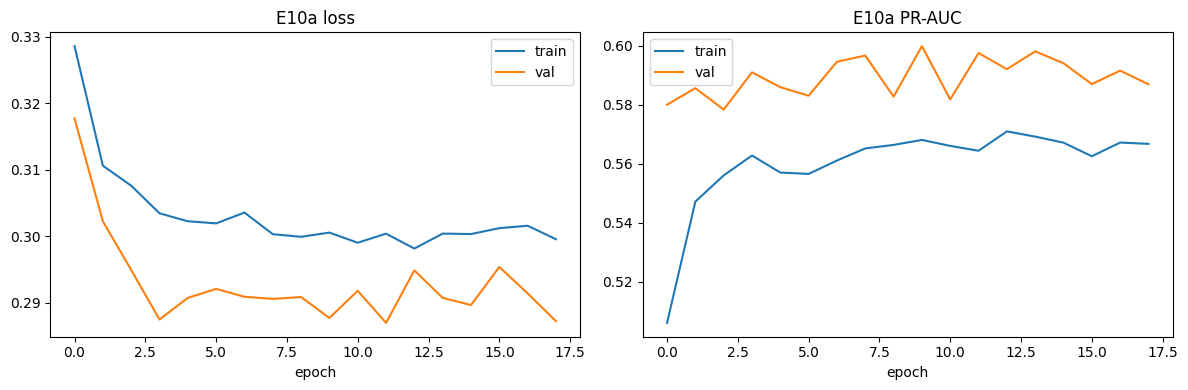


--- E10b: lr=0.01, batch=512 ---
{'exp_id': 'E10b', 'model': 'MLP (Keras)', 'features': 'engineered', 'params': '{"units": [128, 64], "dropout": 0.3, "l2": 0.0001, "lr": 0.01, "epochs_run": 22, "batch": 512}', 'threshold': 0.5, 'accuracy': 0.8906, 'precision': 0.7048, 'recall': 0.3843, 'f1': 0.4974, 'roc_auc': np.float64(0.8753), 'pr_auc': np.float64(0.6058), 'train_time_s': 12.89, 'notes': 'Sweep: lr=0.01, batch=512'}


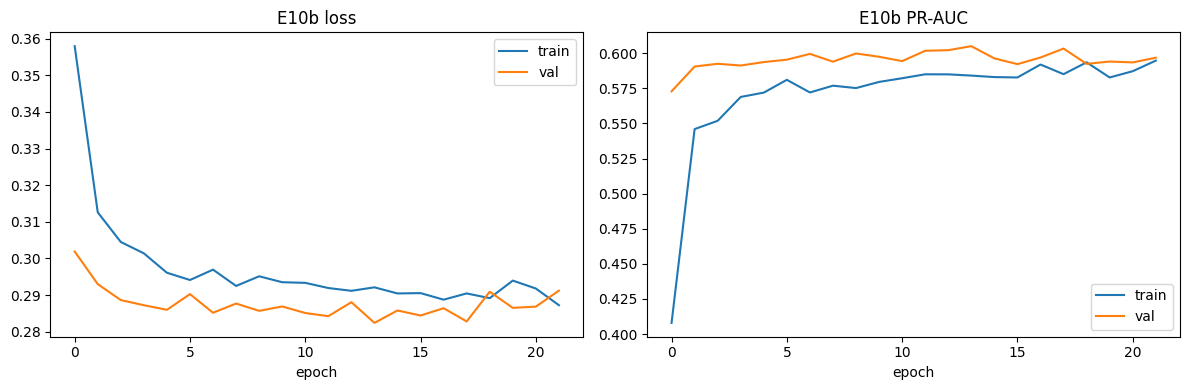


--- E10c: lr=0.001, batch=128 ---


{'exp_id': 'E10c', 'model': 'MLP (Keras)', 'features': 'engineered', 'params': '{"units": [128, 64], "dropout": 0.3, "l2": 0.0001, "lr": 0.001, "epochs_run": 15, "batch": 128}', 'threshold': 0.5, 'accuracy': 0.8909, 'precision': 0.6783, 'recall': 0.4286, 'f1': 0.5253, 'roc_auc': np.float64(0.8742), 'pr_auc': np.float64(0.6), 'train_time_s': 16.95, 'notes': 'Sweep: lr=0.001, batch=128'}


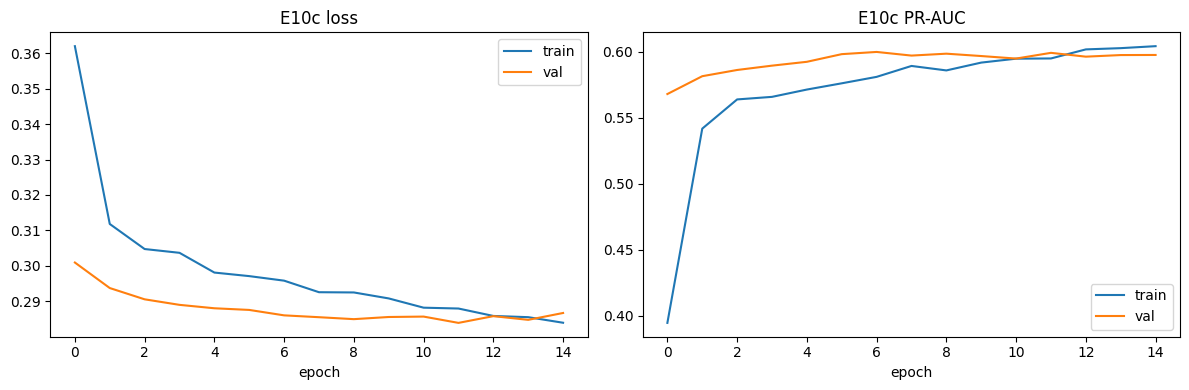


--- E10d: lr=0.001, batch=512 ---
{'exp_id': 'E10d', 'model': 'MLP (Keras)', 'features': 'engineered', 'params': '{"units": [128, 64], "dropout": 0.3, "l2": 0.0001, "lr": 0.001, "epochs_run": 36, "batch": 512}', 'threshold': 0.5, 'accuracy': 0.8903, 'precision': 0.6763, 'recall': 0.4245, 'f1': 0.5216, 'roc_auc': np.float64(0.8742), 'pr_auc': np.float64(0.6048), 'train_time_s': 22.63, 'notes': 'Sweep: lr=0.001, batch=512'}


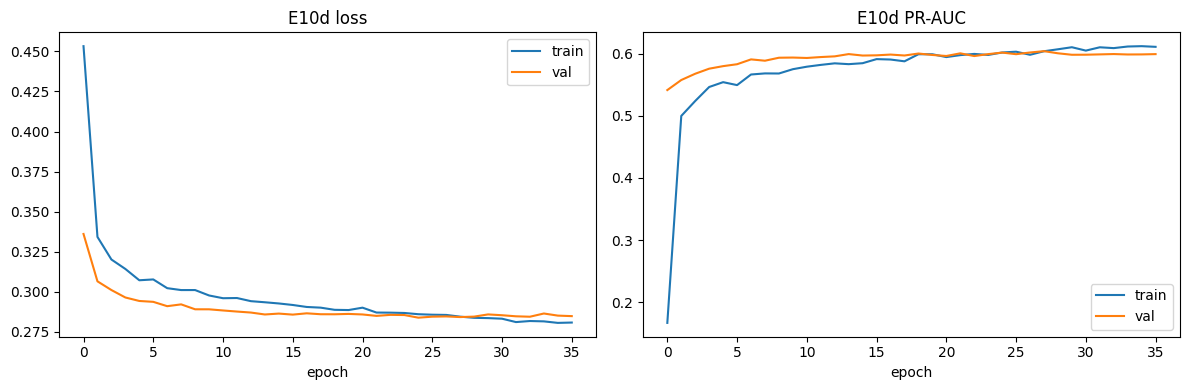


--- E10e: lr=0.0001, batch=128 ---


{'exp_id': 'E10e', 'model': 'MLP (Keras)', 'features': 'engineered', 'params': '{"units": [128, 64], "dropout": 0.3, "l2": 0.0001, "lr": 0.0001, "epochs_run": 78, "batch": 128}', 'threshold': 0.5, 'accuracy': 0.8889, 'precision': 0.6804, 'recall': 0.3984, 'f1': 0.5025, 'roc_auc': np.float64(0.8729), 'pr_auc': np.float64(0.5987), 'train_time_s': 77.37, 'notes': 'Sweep: lr=0.0001, batch=128'}


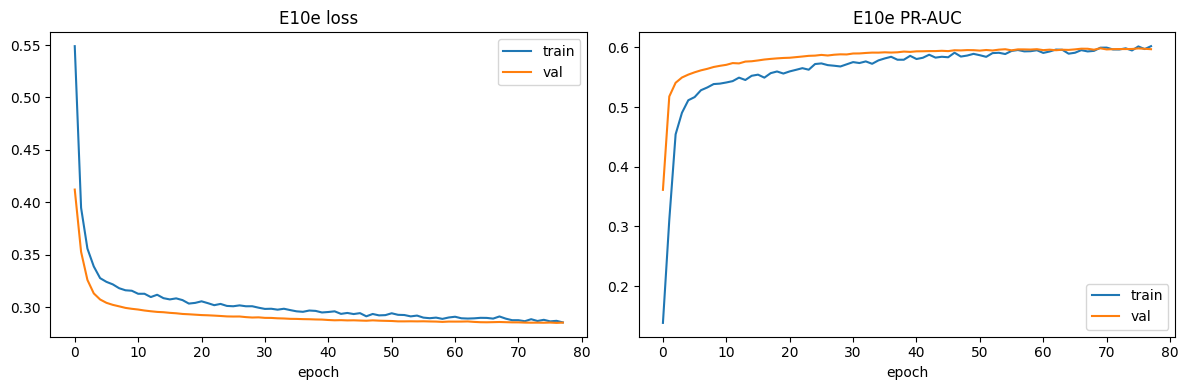


--- E10f: lr=0.0001, batch=512 ---
{'exp_id': 'E10f', 'model': 'MLP (Keras)', 'features': 'engineered', 'params': '{"units": [128, 64], "dropout": 0.3, "l2": 0.0001, "lr": 0.0001, "epochs_run": 100, "batch": 512}', 'threshold': 0.5, 'accuracy': 0.8909, 'precision': 0.6931, 'recall': 0.4044, 'f1': 0.5108, 'roc_auc': np.float64(0.8715), 'pr_auc': np.float64(0.5939), 'train_time_s': 51.08, 'notes': 'Sweep: lr=0.0001, batch=512'}


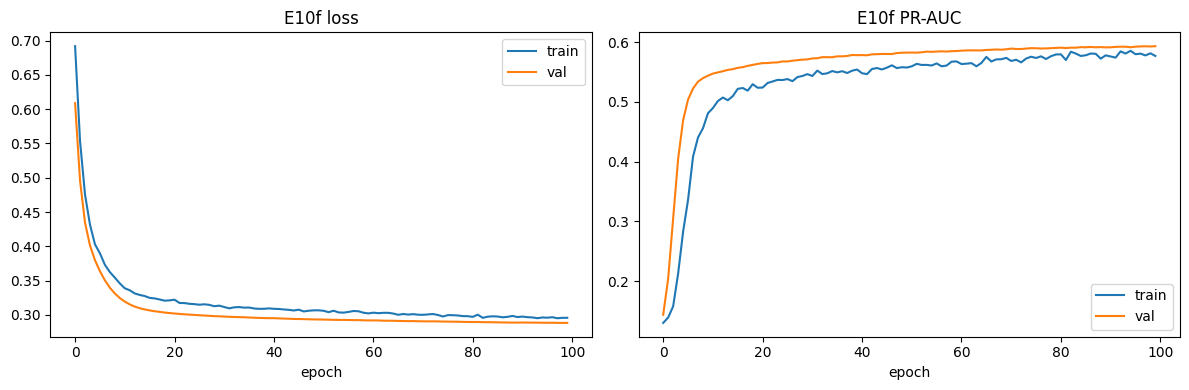

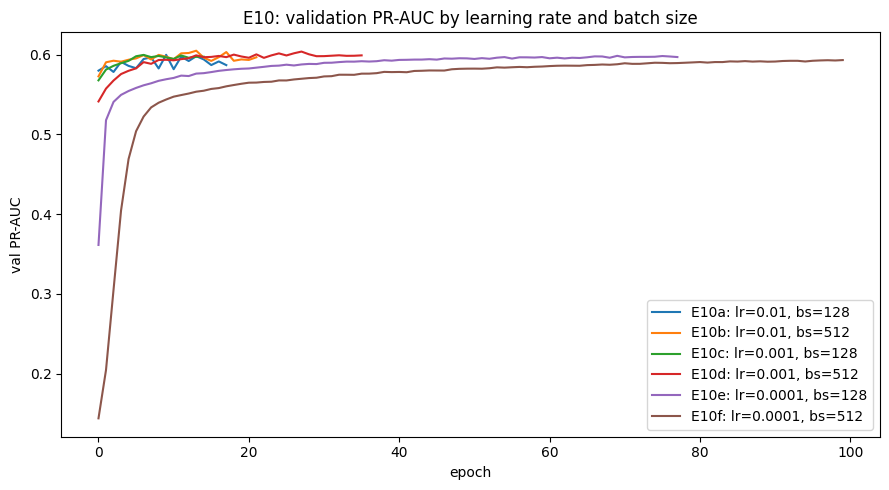

,exp_id,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_s
12,E10a,MLP (Keras),0.5,0.8918,0.6936,0.4145,0.5189,0.8721,0.6004,25.66
13,E10b,MLP (Keras),0.5,0.8906,0.7048,0.3843,0.4974,0.8753,0.6058,12.89
14,E10c,MLP (Keras),0.5,0.8909,0.6783,0.4286,0.5253,0.8742,0.6000,16.95
15,E10d,MLP (Keras),0.5,0.8903,0.6763,0.4245,0.5216,0.8742,0.6048,22.63
16,E10e,MLP (Keras),0.5,0.8889,0.6804,0.3984,0.5025,0.8729,0.5987,77.37
17,E10f,MLP (Keras),0.5,0.8909,0.6931,0.4044,0.5108,0.8715,0.5939,51.08


In [ ]:
e10_runs = {}
tags = iter("abcdef")
for lr in [1e-2, 1e-3, 1e-4]:
    for batch in [128, 512]:
        tag = f"E10{next(tags)}"
        print(f"\n--- {tag}: lr={lr}, batch={batch} ---")
        m, h = train_dl(tag, build_mlp(units=(128, 64), dropout=0.3, l2=1e-4, lr=lr),
                        {"units": [128, 64], "dropout": 0.3, "l2": 1e-4, "lr": lr},
                        epochs=100, batch=batch, early_stop=True,
                        notes=f"Sweep: lr={lr}, batch={batch}")
        e10_runs[tag] = {"model": m, "hist": h, "lr": lr, "batch": batch}

# One plot comparing validation PR-AUC across all six runs
plt.figure(figsize=(9, 5))
for tag, r in e10_runs.items():
    plt.plot(r["hist"].history["val_pr_auc"], label=f"{tag}: lr={r['lr']}, bs={r['batch']}")
plt.title("E10: validation PR-AUC by learning rate and batch size")
plt.xlabel("epoch"); plt.ylabel("val PR-AUC"); plt.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/e10_sweep_comparison.png", dpi=150)
plt.show()

pd.DataFrame(results)[show].query("exp_id.str.startswith('E10')").round(4)

**E10 results:** The learning rate mainly affected the speed and stability of training
rather than final performance. With a learning rate of 0.01, validation PR-AUC
fluctuated noticeably, especially with a batch size of 128, because large updates
overshoot good solutions. A learning rate of 0.001 produced smooth curves and converged
in 15 to 35 epochs. At 0.0001, training was very slow, and E10f reached the 100-epoch
limit while still improving, meaning it underfit within the available budget. Larger
batches gave smoother curves but fewer weight updates per epoch, which slowed learning
at low learning rates.

Despite these differences, final validation PR-AUC only ranged from 0.594 to 0.606.
Every configuration converged towards the same ceiling of about 0.60, which supports
the earlier finding that performance is limited by the information in the features
rather than by model capacity or optimization. E10b reached the highest PR-AUC (0.606),
but its training was less stable, so we select **E10d** (learning rate 0.001,
batch size 512, PR-AUC 0.605) as the base for the final experiment.

### E11: Class weights and threshold tuning for the network
Using the E10d configuration, we test two ways of handling the imbalance, mirroring E6:
- **E11a:** balanced class weights in the loss function, default 0.5 threshold
- **E11b:** no weights, with the threshold tuned to maximize F1 on out-of-fold predictions
  from 5-fold CV on the training set. Each fold trains for the best epoch count found in
  E10d, so no validation data is used to choose the threshold.

Best epoch from E10d: 28
Class weights: {0: np.float32(0.582), 1: np.float32(3.552)}
{'exp_id': 'E11a', 'model': 'MLP (Keras)', 'features': 'engineered', 'params': '{"units": [128, 64], "dropout": 0.3, "l2": 0.0001, "lr": 0.001, "class_weight": "balanced", "epochs_run": 53, "batch": 512}', 'threshold': 0.5, 'accuracy': 0.7773, 'precision': 0.3685, 'recall': 0.8149, 'f1': 0.5075, 'roc_auc': np.float64(0.8735), 'pr_auc': np.float64(0.6069), 'train_time_s': 47.79, 'notes': 'Balanced class weights, threshold 0.5'}


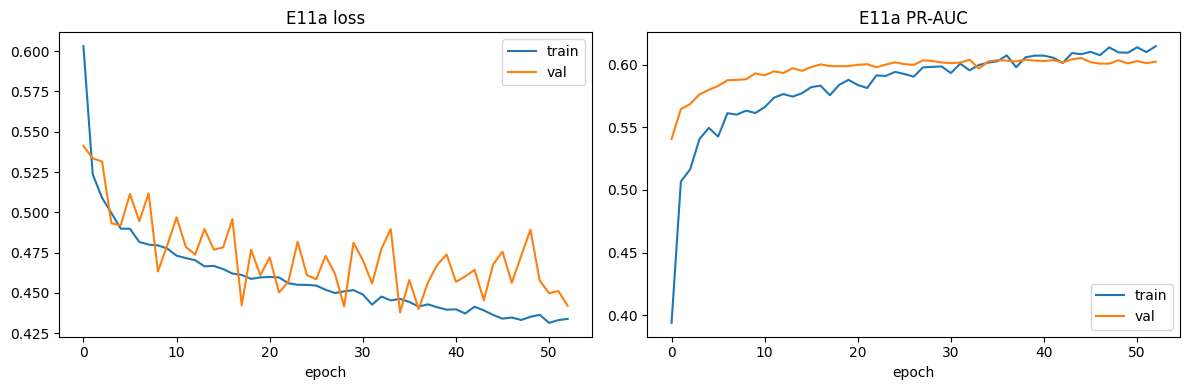

Tuned threshold: 0.3
{'exp_id': 'E11b', 'model': 'MLP (Keras)', 'features': 'engineered', 'params': '{"units": [128, 64], "dropout": 0.3, "l2": 0.0001, "lr": 0.001, "class_weight": null, "epochs_run": 28, "batch": 512}', 'threshold': 0.3, 'accuracy': 0.8725, 'precision': 0.5433, 'recall': 0.5936, 'f1': 0.5673, 'roc_auc': np.float64(0.8742), 'pr_auc': np.float64(0.6048), 'train_time_s': 64.79, 'notes': 'No weights, threshold tuned on 5-fold OOF predictions'}


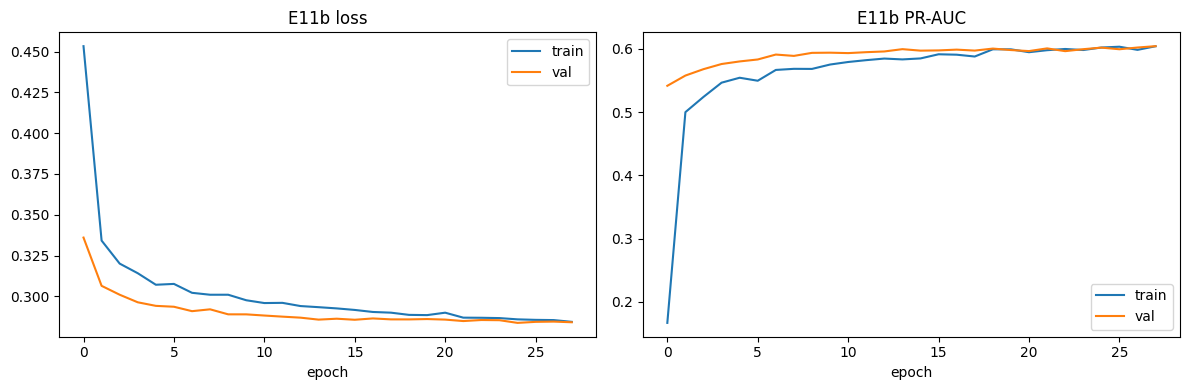

,exp_id,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,train_time_s
18,E11a,MLP (Keras),0.5,0.7773,0.3685,0.8149,0.5075,0.8735,0.6069,47.79
19,E11b,MLP (Keras),0.3,0.8725,0.5433,0.5936,0.5673,0.8742,0.6048,64.79


In [ ]:
LR, BS = 1e-3, 512
best_ep = int(np.argmax(e10_runs["E10d"]["hist"].history["val_pr_auc"])) + 1
print("Best epoch from E10d:", best_ep)

# Balanced class weights
n_pos = ytr.sum(); n_neg = len(ytr) - n_pos
cw = {0: len(ytr) / (2 * n_neg), 1: len(ytr) / (2 * n_pos)}
print("Class weights:", {k: round(v, 3) for k, v in cw.items()})

base_params = {"units": [128, 64], "dropout": 0.3, "l2": 1e-4, "lr": LR}

# E11a: class weights, threshold 0.5
e11a_model, e11a_hist = train_dl("E11a", build_mlp(units=(128, 64), dropout=0.3, l2=1e-4, lr=LR),
                                 {**base_params, "class_weight": "balanced"},
                                 epochs=100, batch=BS, early_stop=True, class_weight=cw,
                                 notes="Balanced class weights, threshold 0.5")

# E11b: no weights, threshold tuned on out-of-fold predictions
start = time.time()
oof = np.zeros(len(ytr))
for tr_idx, va_idx in cv.split(Xtr, ytr):
    m = build_mlp(units=(128, 64), dropout=0.3, l2=1e-4, lr=LR)
    m.fit(make_ds(Xtr[tr_idx], ytr[tr_idx], BS, shuffle=True), epochs=best_ep, verbose=0)
    oof[va_idx] = m.predict(make_ds(Xtr[va_idx], ytr[va_idx], BS), verbose=0).ravel()
t11 = best_threshold(ytr, oof)
print("Tuned threshold:", round(t11, 3))

e11b_model = build_mlp(units=(128, 64), dropout=0.3, l2=1e-4, lr=LR)
e11b_hist = e11b_model.fit(make_ds(Xtr, ytr, BS, shuffle=True),
                           validation_data=make_ds(Xva, yva, BS), epochs=best_ep, verbose=0,
                           callbacks=[tf.keras.callbacks.TensorBoard(log_dir=f"{LOG_DIR}/E11b")])
log_experiment("E11b", "MLP (Keras)", "engineered",
               {**base_params, "class_weight": None, "epochs_run": best_ep, "batch": BS},
               y_val, e11b_model.predict(make_ds(Xva, yva, BS), verbose=0).ravel(),
               time.time() - start, threshold=round(t11, 3),
               notes="No weights, threshold tuned on 5-fold OOF predictions")
plot_curves(e11b_hist, "E11b")

pd.DataFrame(results)[show].query("exp_id.str.startswith('E11')").round(4)

**E11 results:** E11b achieved the best F1 of all experiments (0.567), with balanced
precision (54%) and recall (59%) at a tuned threshold of 0.30. This slightly exceeds
the best tree-based models (F1 0.556 to 0.560).

E11a showed the same over-correction seen in E2 and E4: balanced class weights pushed
recall to 81% but reduced precision to 37%, giving a lower F1 of 0.508 at the default
threshold. Its PR-AUC (0.607) was nonetheless the highest of all runs, confirming that
weighting shifts predictions rather than harming ranking quality. Its loss values are
higher and noisier than other runs because the weighted loss multiplies each positive
example by about 3.55, so the scale differs and a few misclassified positives cause
large swings in validation loss.

Overall, the best network (E11b) and the best traditional model (E6b) are very close:
F1 0.567 vs 0.559, PR-AUC 0.605 vs 0.602, and ROC-AUC 0.874 vs 0.877. These differences
are within the cross-validation noise seen earlier, so neither paradigm clearly dominates.
XGBoost trains about ten times faster and offers clearer feature importance, which are
practical advantages for a policy-facing application.

## 7. Final Evaluation on the Test Set
The test set has not been used for any training or tuning decision. We now evaluate
the best traditional model (E6b, XGBoost) and the best deep learning model (E11b, MLP),
each with the threshold selected from cross-validation, alongside the E1 baseline
for reference.

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

final = {
    "LogReg baseline (E1)": (e1.predict_proba(X_test)[:, 1], 0.5),
    "XGBoost (E6b)": (e6b.predict_proba(X_test)[:, 1], t6b),
    "MLP (E11b)": (e11b_model.predict(make_ds(Xte, yte, BS), verbose=0).ravel(), t11),
}

rows = []
for name, (p, t) in final.items():
    pred = (p >= t).astype(int)
    rows.append({"model": name, "threshold": round(t, 3),
                 "accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred),
                 "roc_auc": roc_auc_score(y_test, p),
                 "pr_auc": average_precision_score(y_test, p)})
test_df = pd.DataFrame(rows)
test_df.to_csv(f"{BASE}/test_results.csv", index=False)
test_df.round(4)

,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,LogReg baseline (E1),0.500,0.8875,0.6953,0.3581,0.4728,0.8505,0.5537
1,XGBoost (E6b),0.251,0.8541,0.4859,0.6237,0.5463,0.8669,0.5799
2,MLP (E11b),0.300,0.8634,0.5135,0.5755,0.5427,0.8664,0.5816


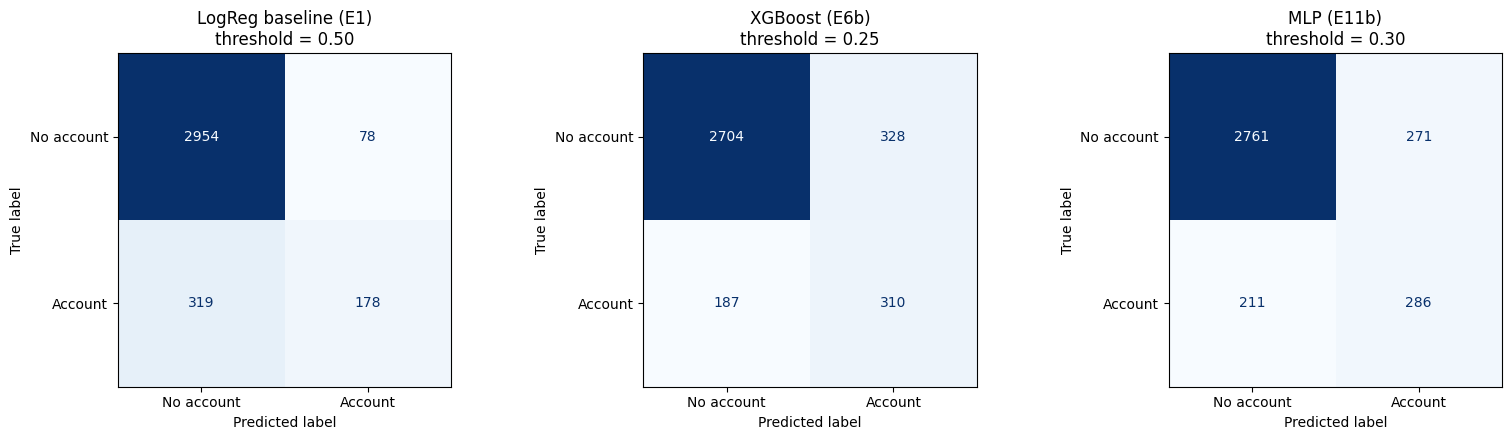

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, (p, t)) in zip(axes, final.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (p >= t).astype(int),
                                            display_labels=["No account", "Account"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name}\nthreshold = {t:.2f}")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/test_confusion_matrices.png", dpi=150)
plt.show()

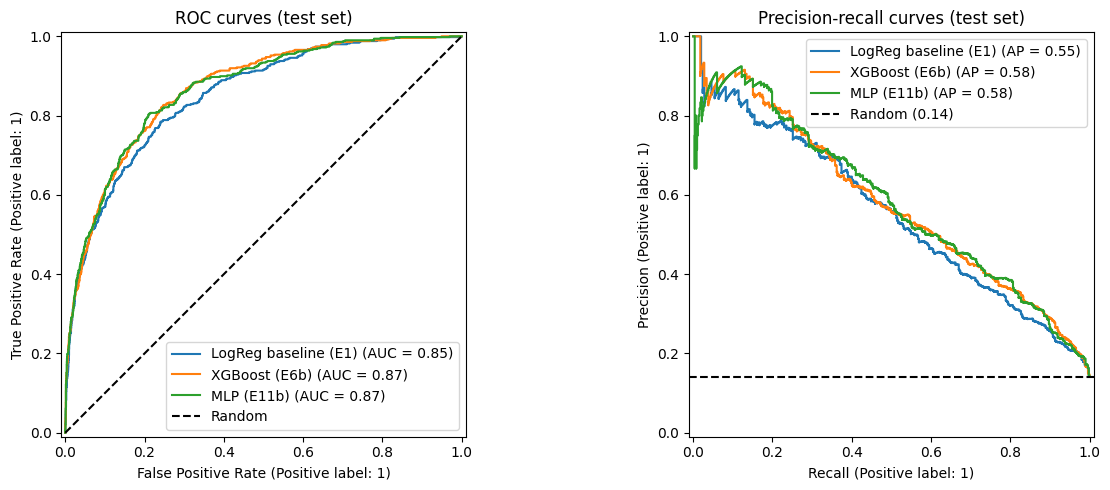

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, (p, t) in final.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[1].axhline(y_test.mean(), color="k", ls="--", label=f"Random ({y_test.mean():.2f})")
axes[0].set_title("ROC curves (test set)"); axes[1].set_title("Precision-recall curves (test set)")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/test_roc_pr_curves.png", dpi=150)
plt.show()

**Test results:** Both final models generalize well. Test scores are slightly below
validation (F1 0.546 and 0.543 vs 0.559 and 0.567; PR-AUC 0.580 and 0.582 vs 0.602 and
0.605). This small drop is expected, since the models were selected using the
validation set. Compared with the E1 baseline, F1 improved from 0.473 to about 0.545
and recall from 36% to 62%: the baseline missed 319 of the 497 account holders,
compared with 187 for XGBoost and 211 for the MLP.

On the test set, XGBoost slightly outperforms the MLP on F1 (0.546 vs 0.543), reversing
the validation ranking. This confirms the two approaches are effectively tied. Their
error profiles differ, however: XGBoost finds more account holders but makes more false
positives (328 vs 271), while the MLP is more conservative. The ROC curves overlap almost
completely, and the precision-recall curves show precision of around 0.8 to 0.9 for the
most confident predictions, falling steadily as recall increases.

The right threshold depends on how the model would be used. For example, if the goal is
to identify unbanked people for outreach, false positives mean those people are missed,
so a higher threshold would be preferable. Threshold selection is therefore a policy
decision as much as a technical one.

## 8. Error Analysis and Interpretation
We look at how performance varies across groups, which features drive predictions,
and whether more data would help (learning curve).

In [ ]:
p_xgb, t_xgb = final["XGBoost (E6b)"]
err = X_test.copy()
err["y"] = y_test.values
err["pred"] = (p_xgb >= t_xgb).astype(int)

def group_report(col):
    rows = []
    for g, d in err.groupby(col):
        rows.append({col: g, "n": len(d),
                     "actual_rate": d["y"].mean(), "predicted_rate": d["pred"].mean(),
                     "precision": precision_score(d["y"], d["pred"], zero_division=0),
                     "recall": recall_score(d["y"], d["pred"], zero_division=0),
                     "f1": f1_score(d["y"], d["pred"], zero_division=0)})
    return pd.DataFrame(rows).sort_values("n", ascending=False).round(3)

for col in ["country", "gender_of_respondent", "location_type", "education_level"]:
    display(group_report(col))

,country,n,actual_rate,predicted_rate,precision,recall,f1
1,Rwanda,1314,0.119,0.119,0.446,0.446,0.446
2,Tanzania,980,0.088,0.099,0.495,0.558,0.525
0,Kenya,911,0.250,0.387,0.490,0.759,0.596
3,Uganda,324,0.080,0.096,0.613,0.731,0.667


,gender_of_respondent,n,actual_rate,predicted_rate,precision,recall,f1
0,Female,2089,0.109,0.121,0.460,0.509,0.483
1,Male,1440,0.187,0.268,0.503,0.721,0.592


,location_type,n,actual_rate,predicted_rate,precision,recall,f1
0,Rural,2156,0.114,0.125,0.422,0.463,0.442
1,Urban,1373,0.183,0.268,0.533,0.781,0.633


,education_level,n,actual_rate,predicted_rate,precision,recall,f1
2,Primary education,1905,0.086,0.058,0.355,0.239,0.286
0,No formal education,661,0.035,0.014,0.333,0.130,0.188
3,Secondary education,648,0.225,0.409,0.411,0.747,0.530
4,Tertiary education,185,0.524,0.757,0.671,0.969,0.793
5,Vocational/Specialised training,125,0.528,0.904,0.566,0.970,0.715
1,Other/Dont know/RTA,5,0.400,0.200,1.000,0.500,0.667


**Error analysis by group:** Performance varies sharply across groups, and the model is
weakest for the populations that financial inclusion policy most aims to reach. F1 is
lower for rural respondents (0.44 vs 0.63 urban), women (0.48 vs 0.59 men) and people
with little education (0.19 with no formal education, 0.29 with primary). Rwanda has
the lowest F1 of the four countries (0.45), compared with 0.60 for Kenya and 0.67 for
Uganda.

The education results show that the model relies heavily on education as a shortcut.
It identifies 97% of account holders with tertiary or vocational training, but only 13%
of those with no formal education. It also over-predicts ownership among educated groups
(for example, 90% predicted vs 53% actual for vocational training). Account holders who
do not fit the typical profile of an educated, formally employed, urban man are
systematically missed, which is also why recall for women (51%) is far below that for
men (72%). This raises fairness concerns if the model were used to target services.
The "Other/Dont know" education group has only 5 test cases, so its results are not reliable.

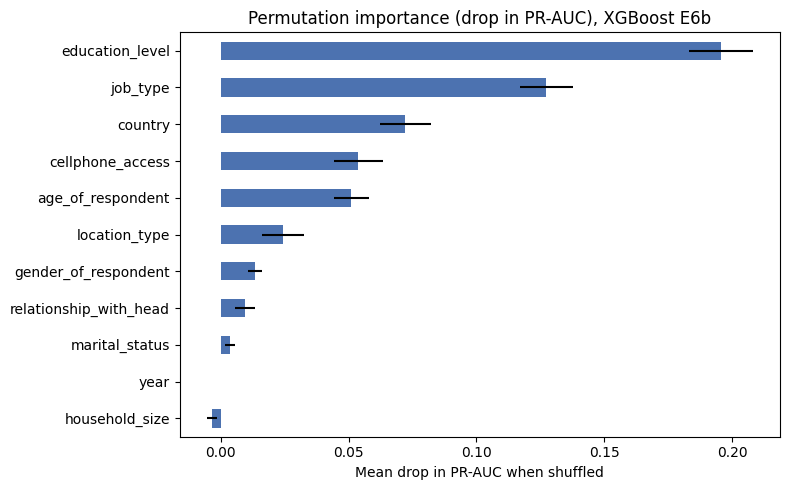

In [ ]:
from sklearn.inspection import permutation_importance

# Permutation importance on the original columns (validation set)
perm = permutation_importance(e6b, X_val, y_val, scoring="average_precision",
                              n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_val.columns).sort_values()

imp.plot(kind="barh", figsize=(8, 5), color="#4C72B0",
         xerr=pd.Series(perm.importances_std, index=X_val.columns)[imp.index])
plt.title("Permutation importance (drop in PR-AUC), XGBoost E6b")
plt.xlabel("Mean drop in PR-AUC when shuffled")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/permutation_importance.png", dpi=150)
plt.show()

**Feature importance:** Permutation importance confirms the EDA. Education level is by
far the most influential feature, followed by job type and country. Age ranks fifth,
even though its distribution barely differed between classes in the EDA, suggesting it
is mainly useful in combination with other features. Household size has slightly
negative importance, meaning it adds no predictive value, and year shows zero importance
because it is removed in the engineered feature set.

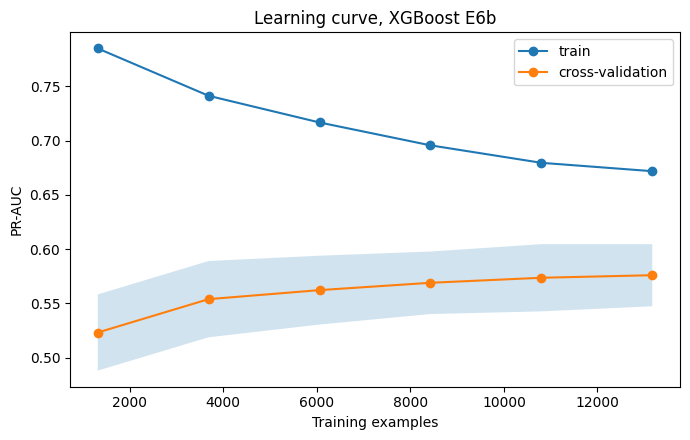

In [ ]:
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(clone(e6b), X_train, y_train, cv=cv,
                                         train_sizes=np.linspace(0.1, 1.0, 6),
                                         scoring="average_precision", n_jobs=-1)
plt.figure(figsize=(7, 4.5))
plt.plot(sizes, train_sc.mean(1), "o-", label="train")
plt.plot(sizes, val_sc.mean(1), "o-", label="cross-validation")
plt.fill_between(sizes, val_sc.mean(1) - val_sc.std(1), val_sc.mean(1) + val_sc.std(1), alpha=0.2)
plt.title("Learning curve, XGBoost E6b")
plt.xlabel("Training examples"); plt.ylabel("PR-AUC"); plt.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/learning_curve_xgboost.png", dpi=150)
plt.show()

**Learning curve:** As the training set grows, training PR-AUC falls from about 0.78 to
0.67 while cross-validation PR-AUC rises from about 0.52 to 0.58, the expected pattern
for a model that generalizes better with more data. The validation curve is flattening,
so additional data of the same kind would likely bring only small gains. A gap of about
0.10 remains, indicating some variance, but the low validation ceiling is better explained
by the label noise identified earlier: when identical profiles have different outcomes,
no amount of data or model capacity can separate them. Richer features (such as income,
mobile money use or distance to a bank) would likely help more than more rows.

In [ ]:
import pickle
MODEL_DIR = f"{BASE}/models"
os.makedirs(MODEL_DIR, exist_ok=True)

# Traditional ML: full pipeline (preprocessing + model) + threshold
with open(f"{MODEL_DIR}/xgboost_e6b.pkl", "wb") as f:
    pickle.dump({"pipeline": e6b, "threshold": t6b}, f)

# Backup: the XGBoost model alone in its own format
e6b.named_steps["model"].save_model(f"{MODEL_DIR}/xgboost_e6b_model.json")

# Deep learning: Keras model + its preprocessor + threshold
e11b_model.save(f"{MODEL_DIR}/mlp_e11b.keras")
with open(f"{MODEL_DIR}/mlp_e11b_preprocessor.pkl", "wb") as f:
    pickle.dump({"preprocessor": prep_dl, "threshold": t11}, f)

print(os.listdir(MODEL_DIR))

['xgboost_e6b.joblib', 'xgboost_e6b.pkl', 'xgboost_e6b_model.json', 'mlp_e11b.keras', 'mlp_e11b_preprocessor.pkl']


## 9. Conclusion
We compared traditional machine learning and deep learning for predicting bank account
ownership across Kenya, Rwanda, Tanzania and Uganda, using 23,524 FinScope survey
responses. Across 21 logged runs, the best traditional model (XGBoost with a tuned
threshold) and the best neural network (a regularized MLP with a tuned threshold)
performed almost identically on the test set (F1 0.546 vs 0.543, ROC-AUC 0.867 vs 0.866),
both well above the logistic regression baseline (F1 0.473).

Three findings stand out. First, handling class imbalance, especially through threshold
tuning, mattered more than model choice or hyperparameter tuning. Second, all models
converged towards the same performance ceiling, which, together with 484 identical
profiles with conflicting labels, points to limits in the features rather than the models.
Third, the models perform worst for rural residents, women, people with little education
and respondents in Rwanda, the groups most relevant to financial inclusion efforts.

Future work should add richer socioeconomic features, explore country-specific thresholds
or models, and apply fairness-aware training before any real-world use.

In [ ]:
import sklearn, xgboost, imblearn, seaborn, matplotlib
for name, mod in [("numpy", np), ("pandas", pd), ("matplotlib", matplotlib), ("seaborn", sns),
                  ("scikit-learn", sklearn), ("xgboost", xgboost),
                  ("imbalanced-learn", imblearn), ("tensorflow", tf)]:
    print(f"{name}=={mod.__version__}")

numpy==2.1.3
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
xgboost==3.4.1
imbalanced-learn==0.14.2
tensorflow==2.21.0
